# QBO wind, temperature and thermal-wind coupling

## Purpose

Evaluate the QBO zonal-wind evolution of the experiments against ERA-Interim and ERA5, the QBO temperature signal, and the thermal-wind consistency of temperature and wind shear.

## Inputs

Model: the 2012-2013 AMIP hindcasts under `INPUT_DATA_ROOT/<case>/post/atm/180x360_aave` (experiments and initial states in `configs/hind_experiment_config.py`). Monthly CMIP-named `ua` and `ta` (`cmip_ts/monthly`, 19 pressure levels). References: ERA5 and ERA-Interim monthly pressure-level `ua` and `ta` (E3SM Diags time series under `OBSERVATION_ROOT`; 0.25 and 0.75 degree, read lazily and subset to the model levels and 5S-5N before computing).

## Method

5S-5N cos-lat weighted zonal mean on the model levels (hPa), for `ua` and `ta`. Amplitudes: half peak-to-peak, RMS, and detrended RMS over the record (for `ta` after removing the month-of-year climatology; the saved section stays raw). Spectral amplitudes need >= 8 years and are not computed for 2012-2013.

Wind. Scores: RMSE/PCC of the sections, averaged over both reanalyses and against `REFERENCE` (ERA5) alone, with a 95% moving-block bootstrap CI (overlapping `BLOCK_LEN`-month blocks; with 24 months this CI is rough). RMSE/PCC over the record mix the initialized memory with the model's own QBO, so memory and timing are scored separately against the mean of both reanalyses:

* `memory_months`: lead months before the profile correlation (10-100 hPa) with the reference stays below `MEMORY_THRESHOLD` for two months;
* westerly/easterly onset month at each level, following the descending shear zone from 10 hPa, and its error;
* descent rate of the westerly zone over 10-50 hPa (km/month, scale height 7 km) and its error.

Temperature. RMSE/PCC and persistence as for the wind, on the T anomalies (`FIELD`/`ANOM_MODE`; the mean vertical structure and seasonal cycle would otherwise dominate). Thermal-wind balance gives a strong negative correlation between T′ and ∂U/∂ln p. The coupling and the amplitudes over the record are properties of the model physics, not of the initial state: they are scored as a pseudo-ensemble check (the reanalyses against the range of the runs in `EXPERIMENTS`). The initial state shows in the errors instead: with α the T′-on-∂U/∂ln p slope of `REFERENCE` (ERA5), α ΔS is the part of a temperature error ΔT supported by the shear error ΔS, and the residual ΔT − α ΔS the part the wind errors do not account for (it also carries any mean bias and departures from the fitted balance), tracked by lead month and grouped by atmospheric initial state.

Attribution (`util/hind_factorial.py`): each score is fitted as μ + atm + lnd over the 8 single runs; the interaction residual is the noise floor setting each effect's 95% interval. Onsets that do not occur within the record are NaN (CTRL and DARTBA at 30-50 hPa), so effects against the piC atmosphere are then not estimable.

## Outputs

`data/hind_atm_eval/qbo/qbo_<SOURCE>_<ua|ta>_<period>.nc` (the `ua` sections are also read by notebook 02), `qbo_<ua|ta>_skill_<REFS>.csv`, `qbo_ua_timing.csv`, `qbo_ua_effects.csv`, `qbo_ta_physics.csv` (per source), `qbo_ta_physics_range.csv` (reanalyses vs model range), `qbo_ta_physics_effects.csv`, `qbo_thermal_wind_consistency.csv`; figures `fig_<name>` in `figure/hind_atm_eval/qbo/` (as `FIGURE_FORMATS`, pdf by default):

1. Sections: U (top row) and T (bottom row) time-pressure sections against `REFERENCE` (optionally `OTHER_REANALYSIS` too), RMSE/PCC annotated; optionally the source − reference differences of U and T.
2. Amplitude: U and T RMS amplitude profiles (T with the seasonal cycle removed).
3. Skill: U and T RMSE/PCC bars, averaged over both reanalyses (their own disagreement drawn as a floor) and vs one reference.
4. Persistence: of the initial vertical profile, and correlation with the reference, vs lead month, for U and T.
5. Vertical coherence: of U and T with `COHERENCE_LEVEL`.
6. Wind phase timing: westerly onset by level and U at 30/50 hPa vs lead month.
7. corr_t[T′, ∂U/∂ln p] by level, mean over `SHEAR_BAND`.
8. T′ vs ∂U/∂ln p in a layer (default 20-50 hPa) for the reanalyses and selected runs.
9. Paper figure, thermal-wind consistency of the temperature errors by atmospheric initial state (`fig_qbo_thermal_wind_consistency.pdf`): ΔT and α ΔS against `REFERENCE` for CTRL10, CAPT10 and DART40, RMS of ΔT − α ΔS vs lead month, months 1-3 profiles. The ERA5 (CAPT) atmosphere cools the 30-70 hPa layer by 8-10 K in the first months with no matching shear error; the DART atmosphere stays near balance. Run with `EXPERIMENTS_FULL` for the range over land initial states.
10. With `EXPERIMENTS_FULL`: factorial scorecards of the wind scores (RMSE, PCC, memory, timing) and of the coupling and amplitude.


## 1. Libraries

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import xarray as xr
from IPython.display import display

## 2. User setup

Paths, experiments and the options shared by the scores and figures. It holds plain values only, so `papermill -p` overrides work. Options of a single figure are set at the top of its cell in section 8.

In [2]:
INPUT_DATA_ROOT = Path("/global/cfs/cdirs/m4849/zhan391/eam_hindcast")
WORK_DIR = Path("/global/cfs/cdirs/m4849/zhan391/work_package/e3sm_dart_analysis")
DIAGNOSTIC_OUTPUT_ROOT = Path("/global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026")
OBSERVATION_ROOT = Path("/global/cfs/cdirs/e3sm/zhan391/data")  # reference-data archive
WORKFLOW_NAME = "hind_atm_eval"

# Experiments: run key (file names, tables) -> figure label. Labels follow fcst_atm_eval: the experiment
# whose initial state the run starts from (CTRL10: piControl, CAPT10: ERA5, DART40: DART), written
# "<atm>A-<lnd>L" when atmosphere and land come from different ones. EXPERIMENTS_FULL (backup) is the full
# atm x lnd factorial, needed for the initial-state attribution (factorial effects and noise floors).
EXPERIMENTS_FULL = {
    "CTRL": "CTRL10-S0",           # piControl atm + piControl lnd
    "DARTOP": "DART40-S0",         # DART atm + DART lnd
    "ERA5OP": "CAPT10-S0",         # ERA5 atm + ERA5-forced lnd
    "ERA5DL": "CAPTA-DARTL-S0",    # ERA5 atm + DART lnd
    "ERA5BL": "CAPTA-CTRLL-S0",    # ERA5 atm + piControl lnd
    "DARTBL": "DARTA-CTRLL-S0",    # DART atm + piControl lnd
    "DARTBA": "CTRLA-DARTL-S0",    # piControl atm + DART lnd
    "DARTAE": "DARTA-CAPTL-S0",    # DART atm + ERA5-forced lnd
}

EXPERIMENTS_FCST = {k: EXPERIMENTS_FULL[k] for k in ("CTRL", "ERA5OP", "DARTOP")}
EXPERIMENTS = EXPERIMENTS_FCST  # or EXPERIMENTS_FULL
REFERENCES = ("ERAI", "ERA5")  # sections for both; skill averaged over them
REFERENCE = "ERA5"             # sections, profiles, thermal-wind errors and single-reference skill against this
OTHER_REANALYSIS = "ERAI"      # drawn as a source in the profiles, timing and scatter
LAT_BAND = (-5.0, 5.0)
# Wind (ua) scores
BLOCK_LEN = 6                  # months per bootstrap block
N_BOOT = 500
MEMORY_THRESHOLD = 0.5       # profile correlation below which the initial QBO phase is lost
TIMING_LEVELS = (10.0, 20.0, 30.0, 50.0, 70.0)  # hPa
# Temperature (ta) and thermal-wind coupling
FIELD = "qbo_anom"          # "qbo" (raw) | "qbo_anom"
ANOM_MODE = "ref_clim"      # "own_clim" | "ref_clim" | "first_month"
COHERENCE_LEVEL = 30.0      # hPa; amplitudes in the coupling table and the coherence figure
SHEAR_BAND = (10.0, 70.0)   # hPa; coupling score and the thermal-wind layer
FORCE_COMPUTE = False
FONT_SCALE = 14
SHOW = True
FIGURE_DPI = 300           # raster formats (and rasterized parts of a pdf)
FIGURE_FORMATS = ("pdf",)  # e.g. ("png",) or ("png", "pdf")
USE_DISTRIBUTED = False  # True: local dask.distributed cluster; worker processes read files in parallel
DASK_WORKERS = 8         # threads (threaded scheduler) or worker processes (distributed); bounds memory

## 3. Paths and modules

In [3]:
repo = WORK_DIR.resolve()
if str(repo / "diagnostic") not in sys.path:
    sys.path.insert(0, str(repo / "diagnostic"))
from configs.output_paths import workflow_output_dirs
from util.dask_helpers import compute_all, configure_dask
from util.hind_factorial import relabel_figure

client = configure_dask(use_distributed=USE_DISTRIBUTED, n_workers=DASK_WORKERS, n_threads=DASK_WORKERS)
data_dir, figure_dir = workflow_output_dirs(WORKFLOW_NAME, 'qbo', output_root=DIAGNOSTIC_OUTPUT_ROOT)
ROOTS = dict(observation_root=OBSERVATION_ROOT)
FACTORIAL = set(EXPERIMENTS) == set(EXPERIMENTS_FULL)  # the atm x lnd attribution needs all 8 runs
SET_NAME = "full" if FACTORIAL else "fcst_aligned" if set(EXPERIMENTS) == set(EXPERIMENTS_FCST) else "subset"
table_dir = data_dir
if not FACTORIAL:  # tables and figures of a subset kept apart from the full set; per-source files are shared
    table_dir, figure_dir = data_dir / SET_NAME, figure_dir / SET_NAME
    for d in (table_dir, figure_dir):
        d.mkdir(exist_ok=True)
print(f"[DATA] {data_dir}\n[TABLE] {table_dir}\n[FIGURE] {figure_dir}")

def save(fig, name):
    relabel_figure(fig, EXPERIMENTS_FULL)  # run keys -> figure labels
    for fmt in FIGURE_FORMATS:
        path = (figure_dir / f"fig_{name}").with_suffix(f".{fmt}")
        fig.savefig(path, dpi=FIGURE_DPI, bbox_inches="tight")
        print(f"[FIGURE] {path}")
    if not SHOW:
        plt.close(fig)

[DATA] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_atm_eval/qbo
[TABLE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_atm_eval/qbo/fcst_aligned
[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/qbo/fcst_aligned


## 4. Read input

Saved diagnostics are reused: fields are opened lazily only for the (source, variable) pairs whose output file is missing (all of them with `FORCE_COMPUTE`), and loaded in the Derive step.

In [4]:
from configs.hind_experiment_config import PERIOD
from util.qbo_diagnostics import open_qbo_input, qbo_section_path

VARIABLES = ("ua", "ta")
SOURCES = (*REFERENCES, *EXPERIMENTS)
paths = {(s, v): qbo_section_path(data_dir, s, v) for v in VARIABLES for s in SOURCES}
inputs = {(s, v): open_qbo_input(s, v, data_root=INPUT_DATA_ROOT, **ROOTS)
          for (s, v), p in paths.items() if FORCE_COMPUTE or not p.exists()}
print(f"[READ] {', '.join(f'{s}/{v}' for s, v in inputs) or 'nothing: every section is saved'}")

[READ] nothing: every section is saved


## 5. Derive

Equatorial time-height section and amplitude profiles per source and variable (for `ta` with the seasonal cycle removed). The expensive reductions of every source and both variables are computed together in one Dask graph (`compute_all`), so reads and reductions run in parallel; the rest works on the loaded results.

In [5]:
from util.qbo_diagnostics import QboAnalyzer, QboConfig

analyzers = {v: QboAnalyzer(QboConfig.for_variable(v, lat_band=LAT_BAND)) for v in VARIABLES}
reduced = compute_all({(s, v): analyzers[v].reduce(da) for (s, v), da in inputs.items()})
derived = {(s, v): analyzers[v].compute_metrics(f"{s}_{v}_{PERIOD}", da).assign_attrs(source=s)
           for (s, v), da in reduced.items()}

## 6. Save

Write the newly derived files, then reload every source from disk so the steps below use the same data as a rerun that reuses the files. Check: RMS amplitude at 30 hPa per source and variable.

In [6]:
for key, ds in derived.items():
    ds.to_netcdf(paths[key])
    print(f"[WRITE] {paths[key]}")
sections = {v: {s: xr.load_dataset(paths[s, v]) for s in SOURCES} for v in VARIABLES}
display(pd.DataFrame({v: {s: float(ds.amp_rms.sel(plev=30)) for s, ds in sections[v].items()}
                      for v in VARIABLES}).add_prefix("amp_rms_30hPa_").round(2))

Warning 3: Cannot find header.dxf (GDAL_DATA is not defined)
ERROR 1: PROJ: proj_create_from_database: Cannot find proj.db


,amp_rms_30hPa_ua,amp_rms_30hPa_ta
ERAI,18.97,1.96
ERA5,19.06,1.99
CTRL,12.83,1.73
ERA5OP,17.71,2.40
DARTOP,18.41,1.63


## 7. Scores

### 7.1 Skill of U and T

RMSE/PCC of every experiment, averaged over `REFERENCES` and against `REFERENCE`, with the 95% block-bootstrap CI; T as anomalies (`FIELD`/`ANOM_MODE`).

In [7]:
from util.qbo_plotting import ua_ta_plotters

UA_TA = dict(ta_field=FIELD, ta_anom_mode=ANOM_MODE)  # T scored and drawn as these anomalies
plotters = ua_ta_plotters(data_dir, **UA_TA)
SKILL_REFS = {"_".join(r): list(r) for r in (REFERENCES, [REFERENCE])}
skill = {v: {} for v in plotters}
for v, pl in plotters.items():
    for tag, refs in SKILL_REFS.items():
        skill[v][tag] = pl.skill_table(refs, EXPERIMENTS, n_boot=N_BOOT, block_len=BLOCK_LEN)
        skill[v][tag].to_csv(table_dir / f"qbo_{v}_skill_{tag}.csv", index=False)
        print(f"[WRITE] {table_dir / f'qbo_{v}_skill_{tag}.csv'}")
display(pd.concat({(v, tag): t.set_index("source")[["rmse", "pcc", "rmse_lo", "rmse_hi", "pcc_lo", "pcc_hi"]]
                   for v, d in skill.items() for tag, t in d.items()}, axis=1).round(2))

[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_atm_eval/qbo/fcst_aligned/qbo_ua_skill_ERAI_ERA5.csv


[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_atm_eval/qbo/fcst_aligned/qbo_ua_skill_ERA5.csv


[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_atm_eval/qbo/fcst_aligned/qbo_ta_skill_ERAI_ERA5.csv


[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_atm_eval/qbo/fcst_aligned/qbo_ta_skill_ERA5.csv


ua                                                           \
       ERAI_ERA5                                       ERA5                 
            rmse   pcc rmse_lo rmse_hi pcc_lo pcc_hi   rmse   pcc rmse_lo   
source                                                                      
CTRL       16.19 -0.33   15.78   17.56  -0.60  -0.20  16.04 -0.35   15.65   
ERA5OP     14.48  0.15   13.38   15.91  -0.08   0.30  14.43  0.14   13.33   
DARTOP     12.71  0.30   11.50   14.23   0.05   0.45  12.64  0.29   11.49   

                ...        ta                                            \
                ... ERAI_ERA5                        ERA5                 
       rmse_hi  ...   rmse_lo rmse_hi pcc_lo pcc_hi  rmse   pcc rmse_lo   
source          ...                                                       
CTRL     17.49  ...      2.89    3.25  -0.44  -0.08  3.14 -0.23    2.91   
ERA5OP   15.93  ...      3.32    4.25  -0.40   0.26  3.88  0.05    3.37   
DARTOP   14.24  ...      2.49    3.06  -0.26   0.12  2.77  0.02    2.59   

                              
                              
       rmse_hi pcc_lo pcc_hi  
source                        
CTRL      3.32  -0.35  -0.07  
ERA5OP    4.27  -0.29   0.30  
DARTOP    3.12  -0.14   0.15  

[3 rows x 24 columns]

### 7.2 Wind memory and phase timing

Memory and phase timing against the mean of `REFERENCES`; factorial effects of the initial states on each wind score.

In [8]:
from util.hind_factorial import factorial_effects
from util.qbo_plotting import qbo_timing_table

timing = qbo_timing_table(data_dir, REFERENCES, EXPERIMENTS, levels_hpa=TIMING_LEVELS,
                          memory_threshold=MEMORY_THRESHOLD)
timing.to_csv(table_dir / "qbo_ua_timing.csv")
print(f"[WRITE] {table_dir / 'qbo_ua_timing.csv'}")
display(timing[["memory_months", "W_onset_10", "W_onset_30", "W_onset_50", "W_onset_70",
                "descent_km_per_month"]].round(1))

SCORE_COLUMNS = {"rmse": ("RMSE (m/s)", False), "pcc": ("PCC", True), "memory_months": ("Memory (months)", True),
                 "abs_W_onset_err_30": ("|W onset error| 30 hPa (months)", False),
                 "abs_W_onset_err_50": ("|W onset error| 50 hPa (months)", False),
                 "descent_err": ("Descent-rate error (km/month)", False)}
scores = pd.concat([skill["ua"]["_".join(REFERENCES)].set_index("source")[["rmse", "pcc"]],
                    timing.loc[list(EXPERIMENTS)]], axis=1)[list(SCORE_COLUMNS)].astype(float)
if FACTORIAL:
    effects = factorial_effects(scores)
    effects.to_csv(table_dir / "qbo_ua_effects.csv", index=False)
    print(f"[WRITE] {table_dir / 'qbo_ua_effects.csv'}")
    display(effects.pivot_table(index="metric", columns="effect", values="estimate", sort=False).round(2))
else:
    print(f"[SKIP] factorial effects: need EXPERIMENTS_FULL (EXPERIMENTS is {SET_NAME})")

[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_atm_eval/qbo/fcst_aligned/qbo_ua_timing.csv


,memory_months,W_onset_10,W_onset_30,W_onset_50,W_onset_70,descent_km_per_month
source,,,,,,
ERAI,24.0,4.0,13.5,16.7,19.1,0.9
ERA5,24.0,4.0,13.4,16.7,19.0,0.9
CTRL,0.0,17.7,NaN,NaN,NaN,NaN
ERA5OP,2.0,2.0,4.9,7.6,15.3,2.0
DARTOP,5.0,2.3,6.2,8.8,15.3,1.7


[SKIP] factorial effects: need EXPERIMENTS_FULL (EXPERIMENTS is fcst_aligned)


### 7.3 Temperature and thermal-wind coupling

Per source: corr_t[T′, ∂U/∂ln p] averaged over `SHEAR_BAND` and the T and U RMS amplitudes at `COHERENCE_LEVEL`; the reanalyses against the range of the runs, and the factorial effects of the initial states.

In [9]:
from util.hind_factorial import model_range_check
from util.qbo_plotting import t_shear_corr_profile

ref_t = sections["ta"][REFERENCE].qbo
physics = pd.DataFrame({s: {
    "corr_T_shear": float(t_shear_corr_profile(data_dir, s, ref_t=ref_t).sel(plev=slice(*SHEAR_BAND)).mean()),
    f"T_amp_{COHERENCE_LEVEL:g}hPa": float(sections["ta"][s].amp_rms.sel(plev=COHERENCE_LEVEL)),
    f"U_amp_{COHERENCE_LEVEL:g}hPa": float(sections["ua"][s].amp_rms.sel(plev=COHERENCE_LEVEL)),
} for s in SOURCES}).T
physics.to_csv(table_dir / "qbo_ta_physics.csv")
check = model_range_check(physics, REFERENCES, EXPERIMENTS)
check.to_csv(table_dir / "qbo_ta_physics_range.csv")
print(f"[WRITE] {table_dir / 'qbo_ta_physics.csv'}, qbo_ta_physics_range.csv")
display(physics.round(2))
display(check.round(2))
if FACTORIAL:
    physics_effects = factorial_effects(physics.loc[list(EXPERIMENTS)])
    physics_effects.to_csv(table_dir / "qbo_ta_physics_effects.csv", index=False)
    print(f"[WRITE] {table_dir / 'qbo_ta_physics_effects.csv'}")
    display(physics_effects.pivot_table(index="metric", columns="effect", values="estimate", sort=False).round(2))
else:
    print(f"[SKIP] factorial effects: need EXPERIMENTS_FULL (EXPERIMENTS is {SET_NAME})")

[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_atm_eval/qbo/fcst_aligned/qbo_ta_physics.csv, qbo_ta_physics_range.csv


,corr_T_shear,T_amp_30hPa,U_amp_30hPa
ERAI,-0.90,1.96,18.97
ERA5,-0.90,1.99,19.06
CTRL,-0.62,1.73,12.83
ERA5OP,-0.67,2.40,17.71
DARTOP,-0.73,1.63,18.41


,model_mean,model_std,model_min,model_max,ERAI,ERAI_in_range,ERA5,ERA5_in_range
metric,,,,,,,,
corr_T_shear,-0.67,0.05,-0.73,-0.62,-0.90,False,-0.90,False
T_amp_30hPa,1.92,0.42,1.63,2.40,1.96,True,1.99,True
U_amp_30hPa,16.32,3.04,12.83,18.41,18.97,False,19.06,False


[SKIP] factorial effects: need EXPERIMENTS_FULL (EXPERIMENTS is fcst_aligned)


## 8. Plot and show

One cell per metric; U and T in one figure where both apply. Each cell starts with its own settings (reference, sources, levels, limits, file name); they default to the user setup: `REFERENCE`, and `sources` = `OTHER_REANALYSIS` + `EXPERIMENTS`.

In [10]:
from util.hind_factorial import plot_factorial_scorecard
from util.qbo_plotting import (plot_amplitude_ua_ta, plot_coherence_ua_ta, plot_hovmoller_ua_ta,
                               plot_persistence_ua_ta, plot_qbo_timing, plot_skill_bars_ua_ta,
                               plot_t_shear_corr_profiles, plot_t_shear_scatter, plot_thermal_wind_consistency)

sources = [OTHER_REANALYSIS, *EXPERIMENTS]  # default sources of the figures below
ta_tag = "raw" if FIELD == "qbo" else ANOM_MODE

### 8.1 Sections

U (top row) and T (bottom row) against `ref`; `OTHER_REANALYSIS` too with `with_other`. T follows `FIELD`/`ANOM_MODE` (anomalies take the climatology of `ref`). With `plot_diffs`, also the source − `ref` sections of each variable.

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/qbo/fcst_aligned/fig_qbo_ua_ta_ref_clim_sections_vs_ERA5.pdf


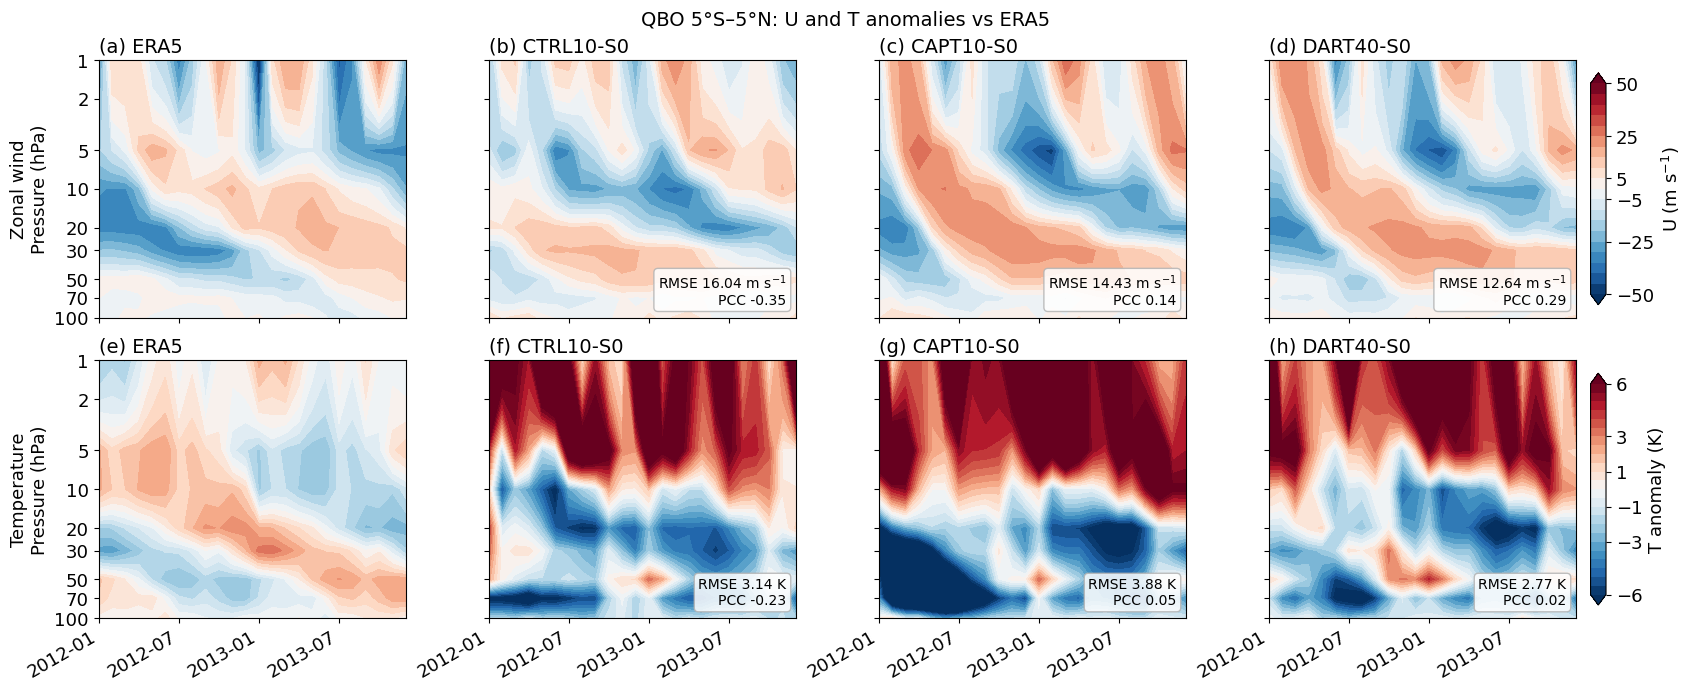

In [11]:
# Settings
ref = REFERENCE
with_other = False   # also draw OTHER_REANALYSIS
plot_diffs = False   # also draw the source − ref sections of U and T
ylim = (100, 1)      # hPa
time_every = 6       # months between time ticks

srcs = [*([OTHER_REANALYSIS] if with_other else []), *EXPERIMENTS]
save(plot_hovmoller_ua_ta(data_dir, ref, srcs, ylim=ylim, time_every=time_every, font_scale=FONT_SCALE, **UA_TA),
     f"qbo_ua_ta_{ta_tag}_sections_vs_{ref}.png")
if plot_diffs:
    for v, pl in plotters.items():
        save(pl.plot_timepressure_diffs(ref, [s for s in sources if s != ref], time_every=time_every,
                                        font_scale=FONT_SCALE, w_per_col=7, h_per_row=4),
             f"qbo_{v}{'_' + ta_tag if v == 'ta' else ''}_diffs_vs_{ref}.png")

### 8.2 Amplitude

RMS amplitude profiles of U and of T (seasonal cycle removed).

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/qbo/fcst_aligned/fig_qbo_ua_ta_amplitude_rms.pdf


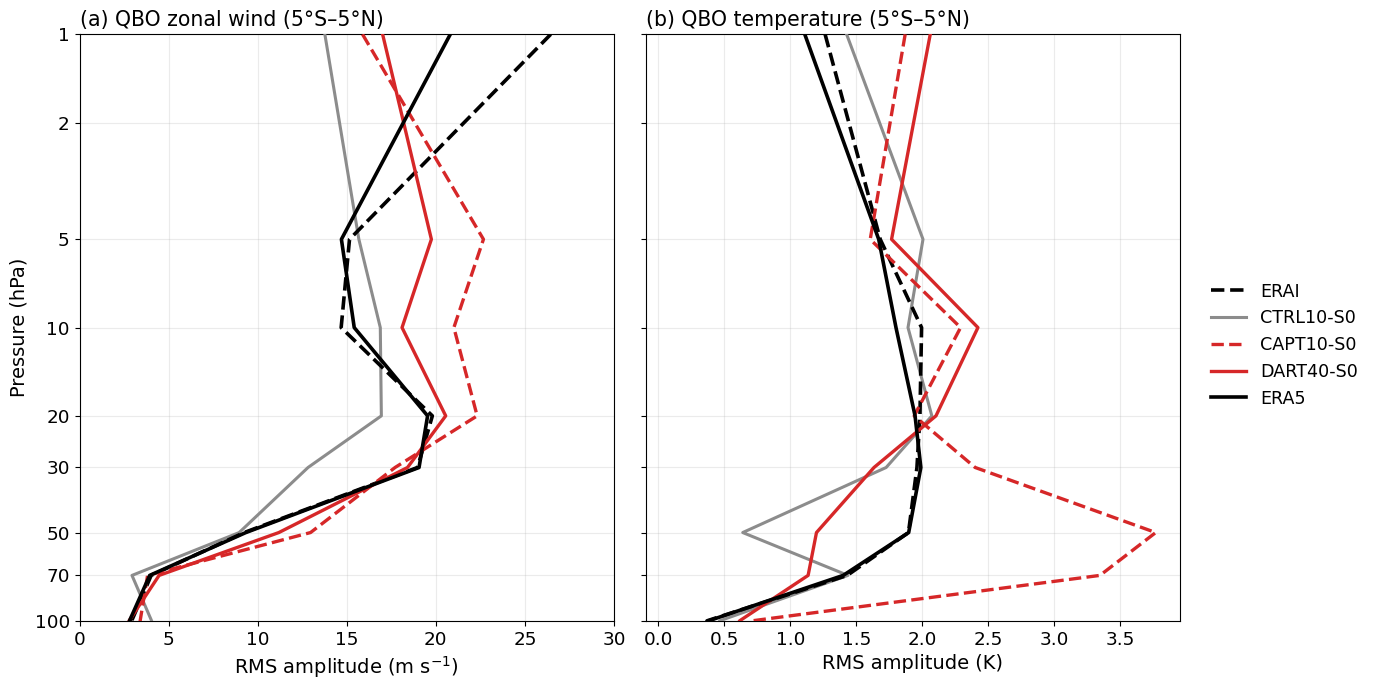

In [12]:
# Settings
ref = REFERENCE
srcs = sources
amplitude_method = "rms"   # "p2p" | "rms" | "rms_detrend"
xlim = ((0, 30), None)     # (U, T); None: automatic

save(plot_amplitude_ua_ta(data_dir, ref, srcs, amplitude_method=amplitude_method, xlim=xlim, font_scale=FONT_SCALE,
                          **UA_TA), f"qbo_ua_ta_amplitude_{amplitude_method}.png")

### 8.3 Skill

RMSE (left) and PCC (right) of U (top) and T (bottom), sources ordered by U RMSE; one figure per reference set of the 7.1 tables (`SKILL_REFS`: averaged over `REFERENCES`, and `REFERENCE` alone).

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/qbo/fcst_aligned/fig_qbo_ua_ta_skillbars_ERAI_ERA5.pdf


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/qbo/fcst_aligned/fig_qbo_ua_ta_skillbars_ERA5.pdf


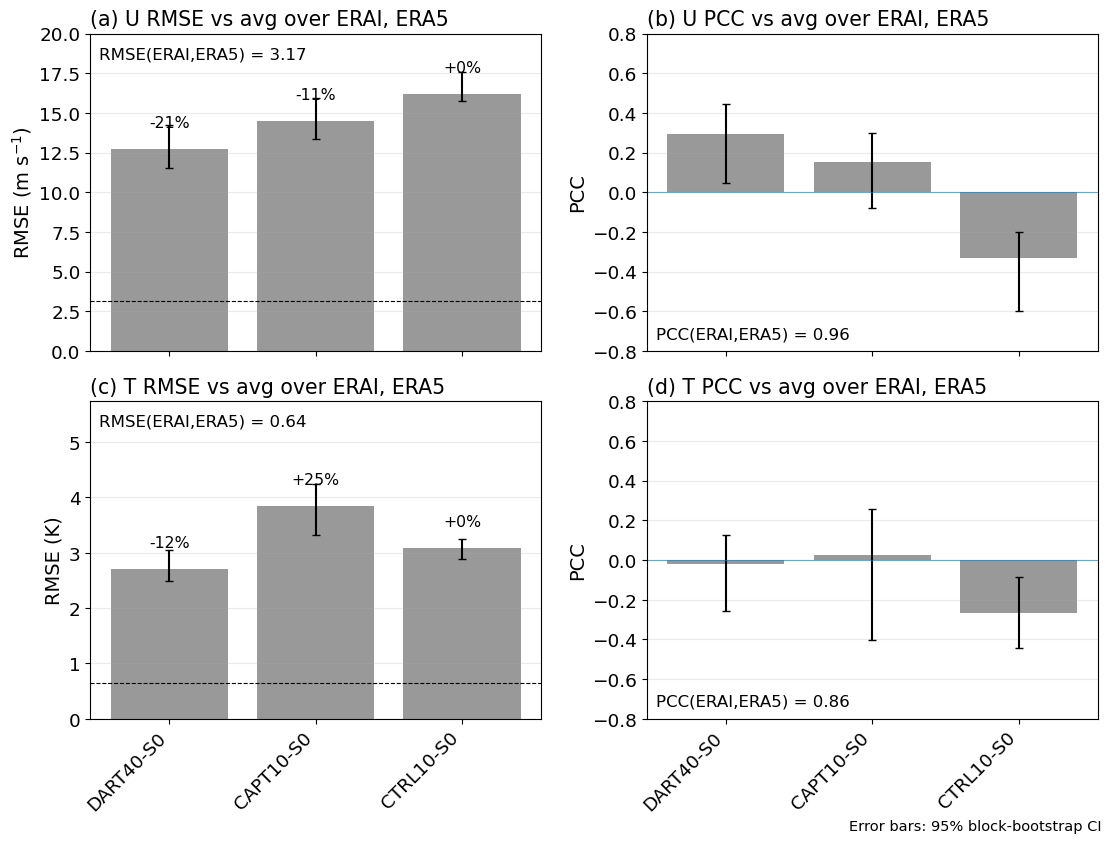

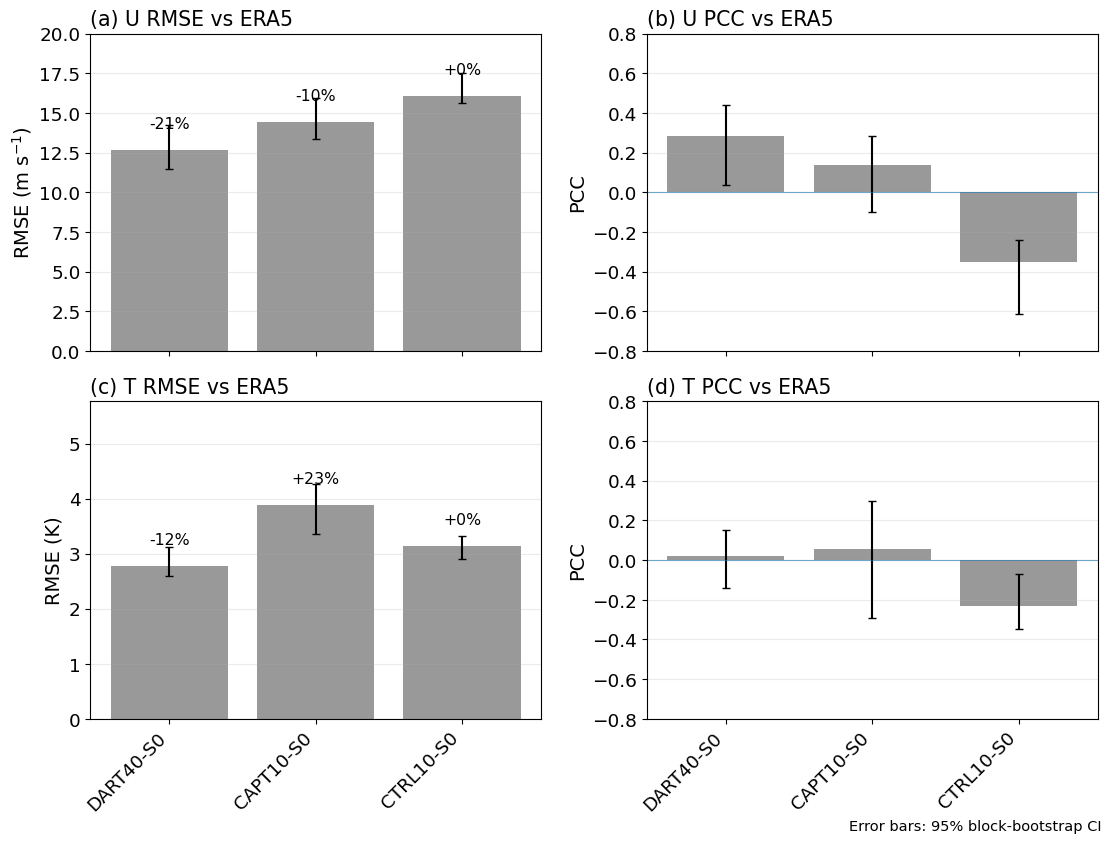

In [13]:
# Settings
rmse_ylim = ((0, 20), None)   # (U, T); None: automatic
pcc_ylim = (-0.8, 0.8)

for tag, refs in SKILL_REFS.items():
    save(plot_skill_bars_ua_ta(data_dir, refs, EXPERIMENTS, tables={v: skill[v][tag] for v in skill},
                               rmse_ylim=rmse_ylim, pcc_ylim=pcc_ylim, font_scale=FONT_SCALE, **UA_TA),
         f"qbo_ua_ta_skillbars_{tag}.png")

### 8.4 Persistence

Correlation over levels of each profile with the initial `init_months` profile (top) and with `ref` at the same lead (bottom), for U (left) and T (right).

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/qbo/fcst_aligned/fig_qbo_ua_ta_persistence_vs_ERA5.pdf


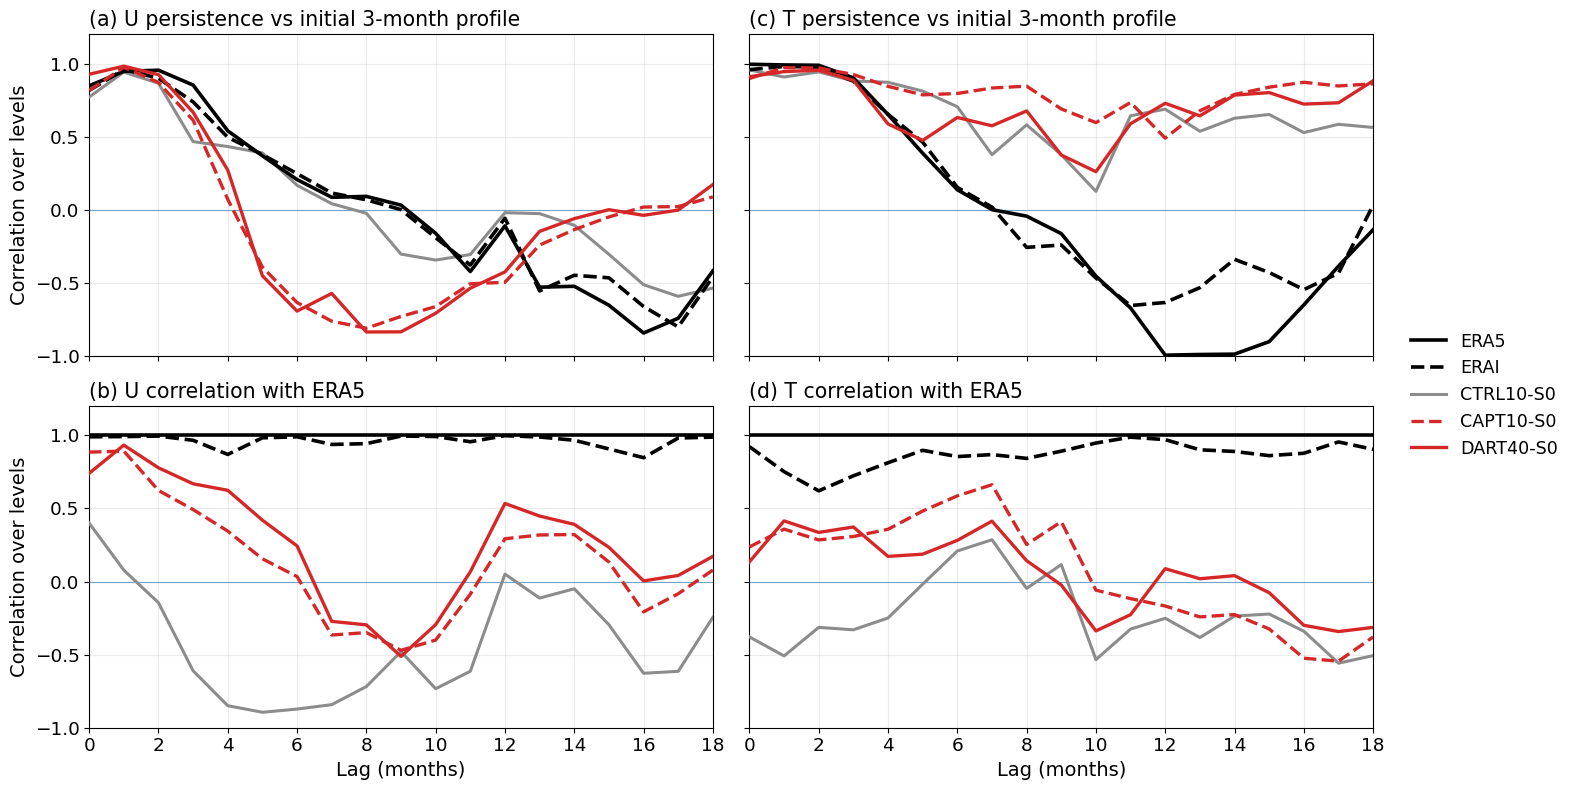

In [14]:
# Settings
ref = REFERENCE
srcs = sources
init_months = 3   # months averaged into the initial profile
max_lag = 18      # months

save(plot_persistence_ua_ta(data_dir, ref, srcs, init_months=init_months, max_lag=max_lag, font_scale=FONT_SCALE,
                            **UA_TA), f"qbo_ua_ta_persistence_vs_{ref}.png")

### 8.5 Vertical coherence

Correlation over time of U and of T at each level with the same variable at `ref_level_hpa`.

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/qbo/fcst_aligned/fig_qbo_ua_ta_ref_clim_coherence_30hPa.pdf


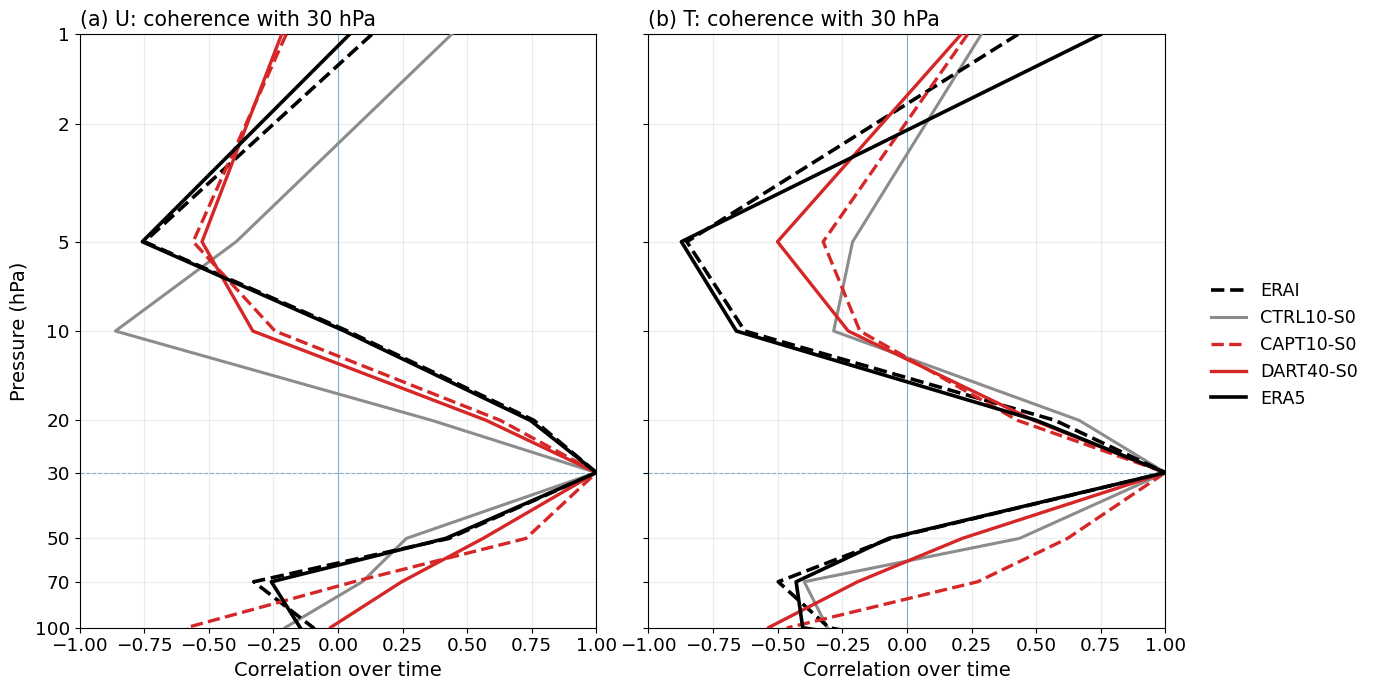

In [15]:
# Settings
ref = REFERENCE
srcs = sources
ref_level_hpa = COHERENCE_LEVEL

save(plot_coherence_ua_ta(data_dir, ref, srcs, ref_level_hpa=ref_level_hpa, font_scale=FONT_SCALE, **UA_TA),
     f"qbo_ua_ta_{ta_tag}_coherence_{ref_level_hpa:g}hPa.png")

### 8.6 Wind phase timing

Westerly onset by level (from the 7.2 timing table) and U at `levels_hpa` vs lead month (onsets are defined by the wind only).

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/qbo/fcst_aligned/fig_qbo_ua_timing.pdf


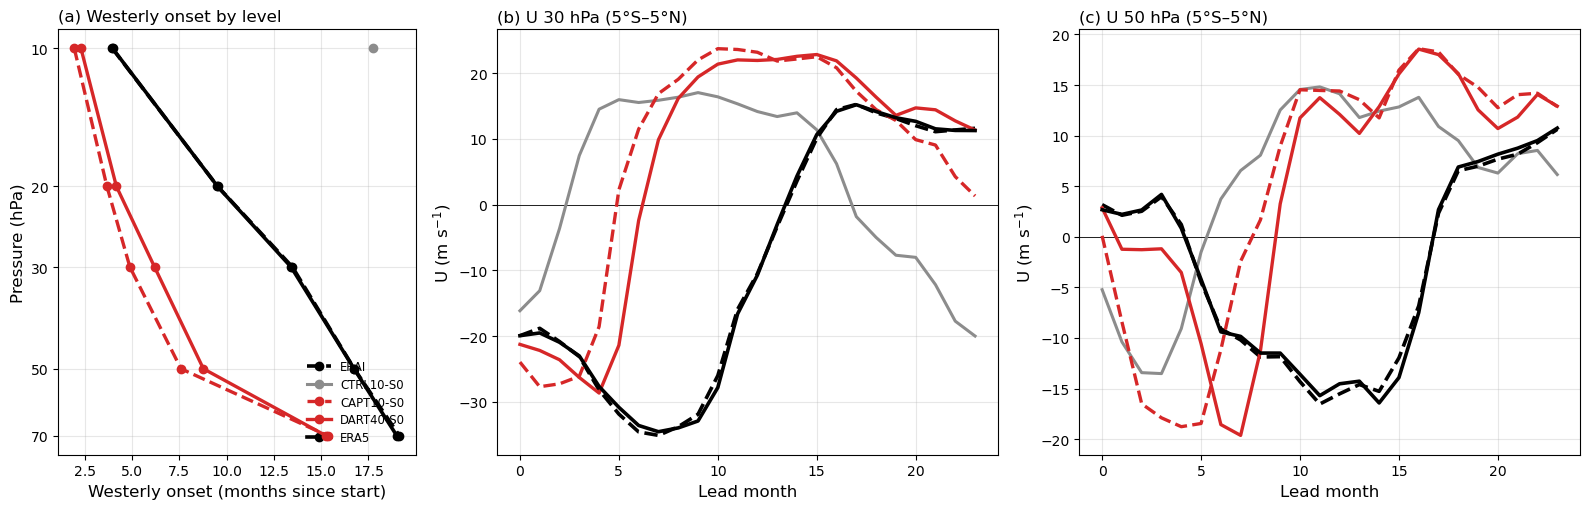

In [16]:
# Settings
ref = REFERENCE
srcs = sources
levels_hpa = (30.0, 50.0)   # U time series panels

save(plot_qbo_timing(data_dir, ref, srcs, timing, levels_hpa=levels_hpa), "qbo_ua_timing.png")

### 8.7 Thermal-wind coupling by level

corr_t[T′, ∂U/∂ln p] per level; the legend gives the mean over `band_hpa` (shaded); T′ are anomalies from the `ref` monthly climatology.

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/qbo/fcst_aligned/fig_qbo_t_shear_corr_profiles.pdf


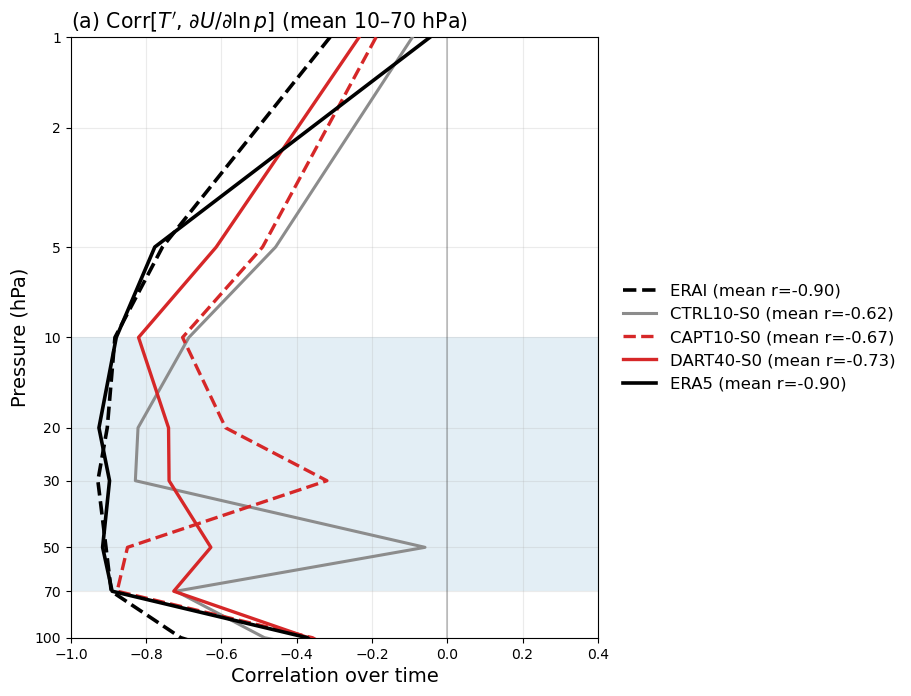

In [17]:
# Settings
ref = REFERENCE
srcs = sources
band_hpa = SHEAR_BAND
xlim = (-1.0, 0.4)

save(plot_t_shear_corr_profiles(data_dir, ref, srcs, band_hpa=band_hpa, xlim=xlim, font_scale=FONT_SCALE),
     "qbo_t_shear_corr_profiles.png")

### 8.8 Thermal-wind scatter

T′ vs ∂U/∂ln p in `layer_hpa` for both reanalyses and `runs`, with the regression slope.

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/qbo/fcst_aligned/fig_qbo_t_shear_scatter_20-50hPa.pdf


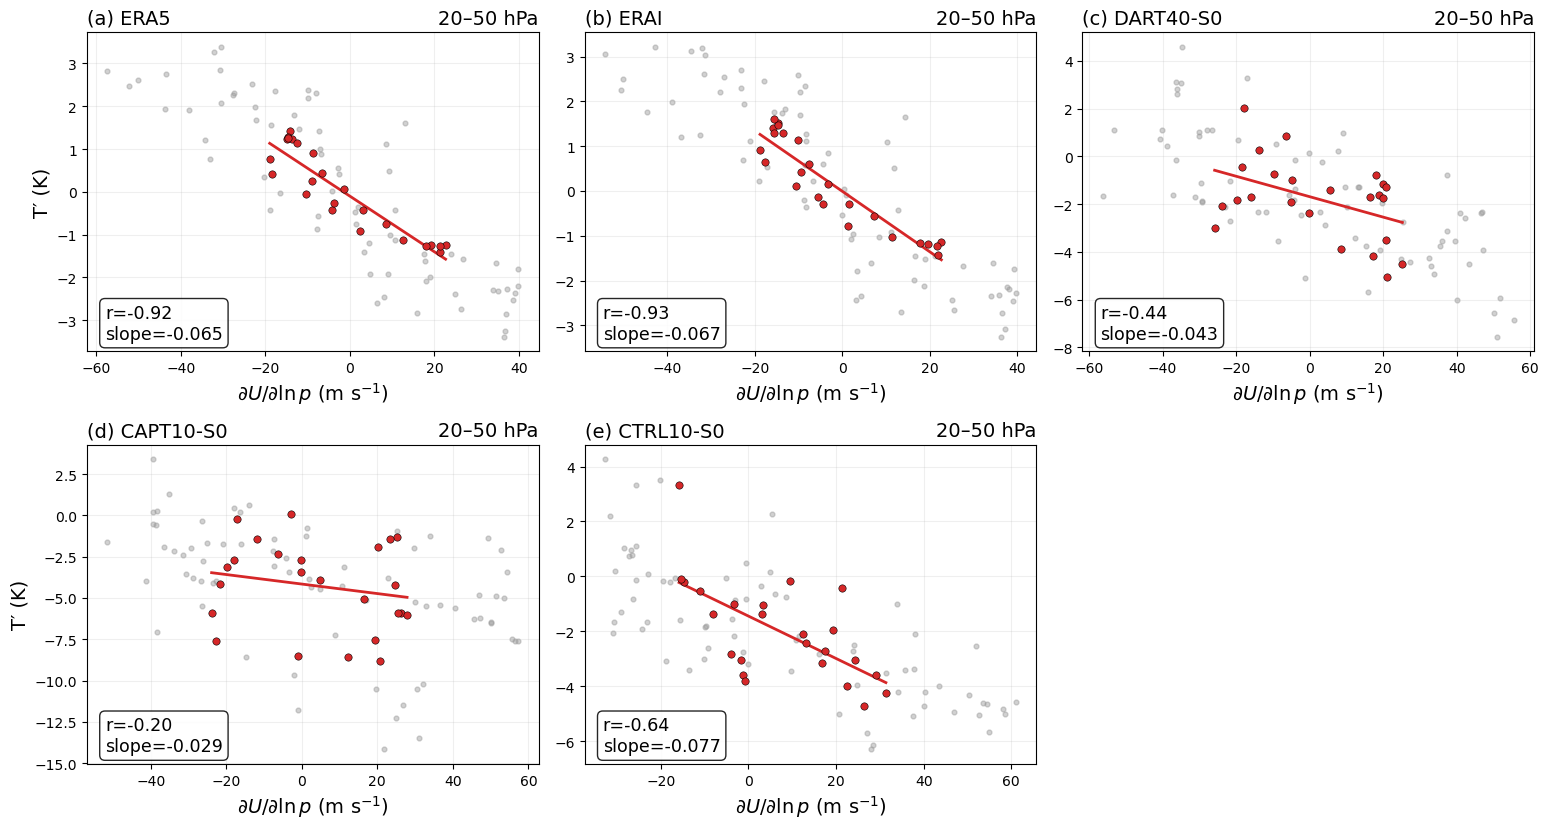

In [18]:
# Settings
ref = REFERENCE
runs = ("DARTOP", "ERA5OP", "CTRL", "DARTBA")   # runs not in EXPERIMENTS are skipped
layer_hpa = (20.0, 50.0)

srcs = [OTHER_REANALYSIS, *(s for s in runs if s in EXPERIMENTS)]
save(plot_t_shear_scatter(data_dir, ref, srcs, layer_hpa=layer_hpa, font_scale=FONT_SCALE),
     f"qbo_t_shear_scatter_{layer_hpa[0]:g}-{layer_hpa[1]:g}hPa.png")

### 8.9 Thermal-wind consistency of the temperature errors (paper figure)

ΔT vs α ΔS against `ref` by atmospheric initial state (`atm_groups`; sections and profiles of `runs`: CTRL10, CAPT10, DART40); the per-run balance table is written alongside. Symbols and α are explained in the caption, not in the figure (the cell prints α).

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/qbo/fcst_aligned/fig_qbo_thermal_wind_consistency.pdf
[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_atm_eval/qbo/fcst_aligned/qbo_thermal_wind_consistency.csv
alpha = -0.068 K s/m (regression of T' on dU/dln p in ERA5, 10-70 hPa; for the caption)


,group,r_dT_dS,slope_dT_dS,residual_rms_m1-6,residual_rms_m7-24,mean_dT_m1-6
source,,,,,,
CTRL,piControl atm IC,-0.82,-0.07,3.47,2.85,-2.05
ERA5OP,ERA5 atm IC (CAPT),-0.46,-0.06,7.94,4.24,-6.19
DARTOP,DART atm IC,-0.71,-0.07,2.72,3.03,-1.53


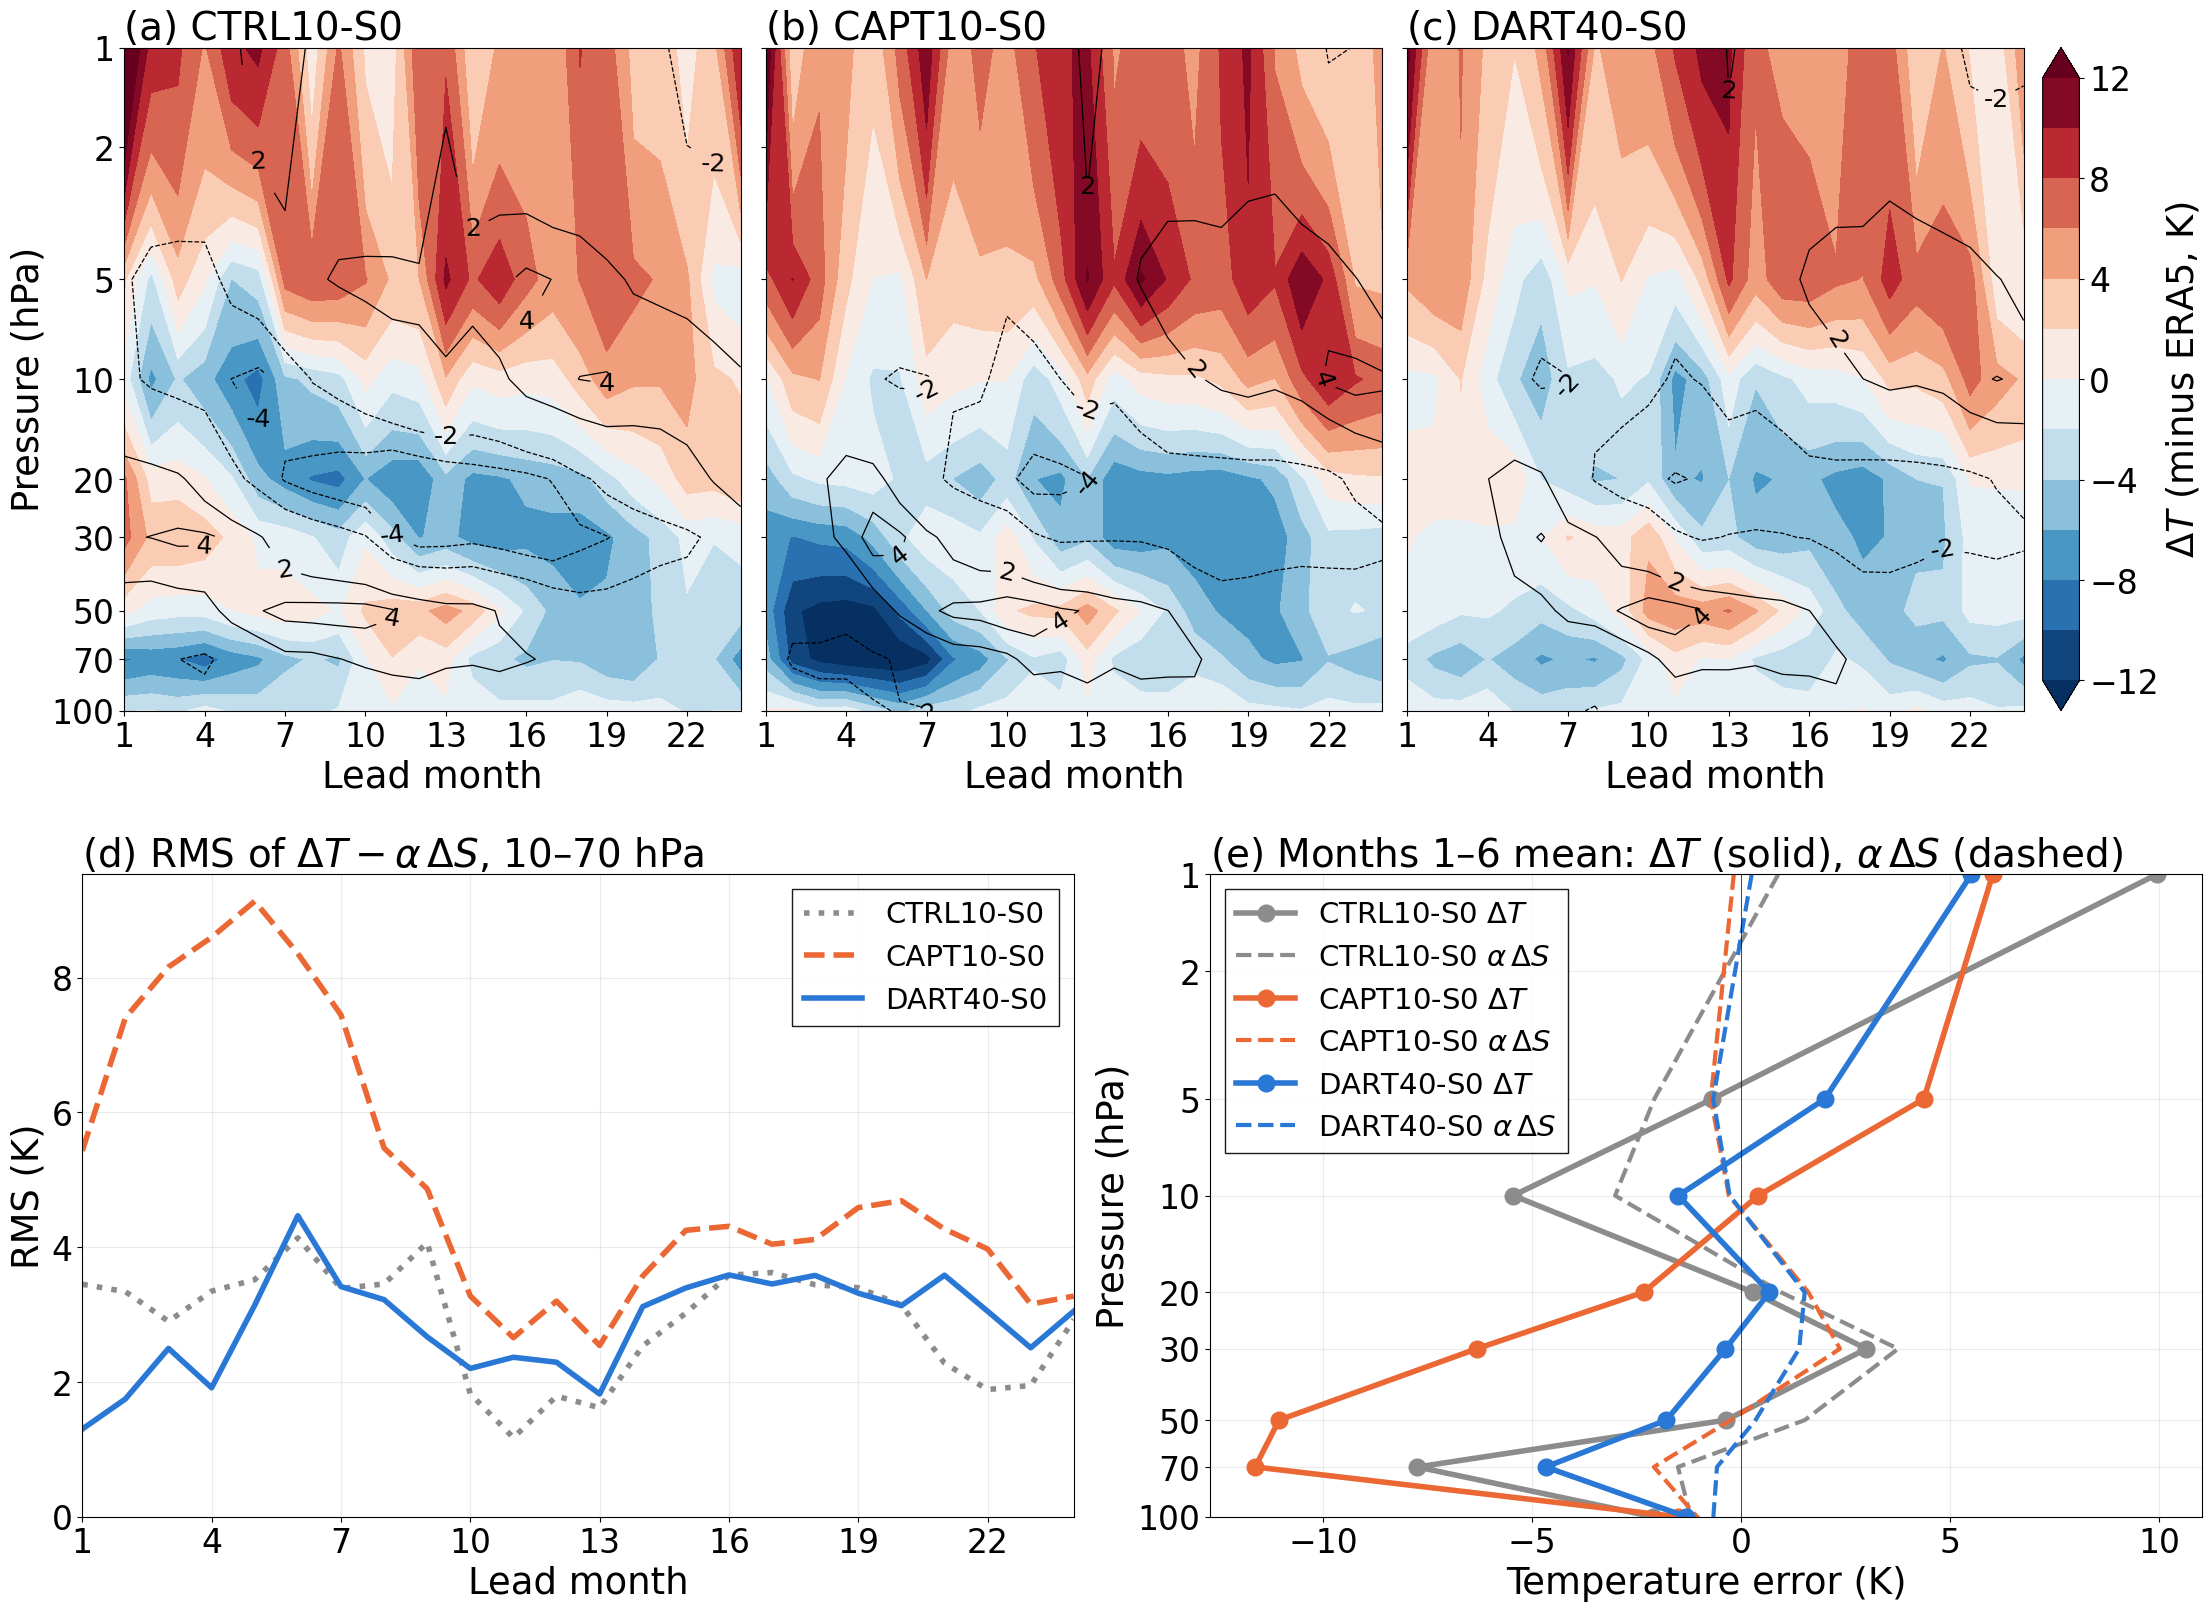

In [19]:
# Settings
ref = REFERENCE                       # errors ΔT, ΔS against this reanalysis, and α fitted on it
runs = ("CTRL", "ERA5OP", "DARTOP")   # sections (a-c) and early-lead profiles: CTRL10-S0, CAPT10-S0, DART40-S0
atm_groups = {"piControl atm IC": ("CTRL", "DARTBA"), "ERA5 atm IC (CAPT)": ("ERA5OP", "ERA5DL", "ERA5BL"),
              "DART atm IC": ("DARTOP", "DARTBL", "DARTAE")}   # all runs grouped by atmospheric initial state
colors = ("0.55", "#eb6834", "#2a78d6")   # per atm_groups entry: piControl gray, ERA5 orange, DART blue
linestyles = (":", "--", "-")           # per atm_groups entry, panel (d)
layer_hpa = SHEAR_BAND                # layer of α and of the residual RMS
profile_months = 6                    # lead months averaged in the profiles
floor = None                          # e.g. OTHER_REANALYSIS: draw it vs ref as the reanalysis floor
fontsize = 28                         # panel titles (pt); labels, ticks and legends scale from it
figsize = (22, 16)                    # inches; fixed, so a larger fontsize gives relatively larger text
row_heights = (8.1, 7.9)              # inches of the top (a-c) and bottom (d, e) rows (sum = figsize[1])
# Panels (d) and (e); the legend labels of (d) are the atm_groups names
linewidth = 4.0                       # lines (dashed α ΔS profiles at 0.75 of it)
markersize = 12                       # profile markers
ylim = (100, 1)                       # hPa, sections (a-c) and profiles (e)
legend_fontsize = None                # None: 0.75 * fontsize
legend_loc = ("upper right", "upper left")   # (d), (e)
legend_frame = True                   # closed box around the legends

groups = {g: [s for s in v if s in EXPERIMENTS] for g, v in atm_groups.items()}
runs_in = [s for s in runs if s in EXPERIMENTS]
fig, balance = plot_thermal_wind_consistency(data_dir, ref, {g: v for g, v in groups.items() if v}, refs=[ref],
                                             layer_hpa=layer_hpa, profile_months=profile_months, floor=floor,
                                             font_scale=fontsize, figsize=figsize, linewidth=linewidth,
                                             markersize=markersize, legend_fontsize=legend_fontsize,
                                             legend_loc=legend_loc, legend_frame=legend_frame,
                                             ylim=ylim, row_heights=row_heights,
                                             colors=colors, linestyles=linestyles,
                                             sections=runs_in, profile_sources=runs_in)
save(fig, "qbo_thermal_wind_consistency.png")
balance.to_csv(table_dir / "qbo_thermal_wind_consistency.csv")
print(f"[WRITE] {table_dir / 'qbo_thermal_wind_consistency.csv'}")
print(f"alpha = {balance.attrs['alpha']:.3f} K s/m (regression of T' on dU/dln p in {ref}, {min(layer_hpa):g}-{max(layer_hpa):g} hPa; for the caption)")
display(balance.round(2))

### 8.10 Factorial scorecards

Initial-state attribution of the wind scores and of the coupling and amplitude; needs `EXPERIMENTS_FULL`.

In [20]:
# Settings
wind_title = "QBO wind: initial-state attribution"
physics_title = "QBO temperature and thermal-wind coupling: initial-state attribution"

if FACTORIAL:
    save(plot_factorial_scorecard(scores, effects, labels={k: v[0] for k, v in SCORE_COLUMNS.items()},
                                  higher_is_better={k: v[1] for k, v in SCORE_COLUMNS.items()}, title=wind_title),
         "qbo_ua_factorial.png")
    save(plot_factorial_scorecard(physics.loc[list(EXPERIMENTS)], physics_effects, title=physics_title),
         "qbo_ta_physics_factorial.png")
else:
    print(f"[SKIP] factorial scorecards: need EXPERIMENTS_FULL (EXPERIMENTS is {SET_NAME})")

[SKIP] factorial scorecards: need EXPERIMENTS_FULL (EXPERIMENTS is fcst_aligned)
